# Behavioral verification: comparable, indexed experiments

This notebook runs the reusable package implementation. P1 is a per-user
classifier trained with same-card impostors. P2 enrolls on genuine attempts
1–5 and probes genuine 6–10 plus same-card impostors. All scores retain
`(User ID, Is Genuine, Test ID)`; larger means more genuine.

Settings are fixed baselines, not selected on these evaluation results.
EER uses the complete ROC and the discrete nearest-crossing convention.
FRR at a target FAR is an evaluation-curve statistic, not a calibrated
deployment guarantee. A deployable threshold needs separate calibration.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from behavioral_ml import evaluation, experiment
from behavioral_ml.etl import infer_typist_candidates, load_data
from behavioral_ml.features import build_feature_sets

data_dir = Path(os.environ.get("KMT_DATA_DIR", "../data/raw_kmt_dataset"))
mouse_events, key_events = load_data(data_dir)
feature_sets = build_feature_sets(mouse_events, key_events)
assert len(feature_sets["keys"]) == 1760
assert not np.isinf(feature_sets["keys_mouse"].to_numpy(dtype=float)).any()
pd.DataFrame({name: {"attempts": len(frame), "features": frame.shape[1]}
              for name, frame in feature_sets.items()}).T


,attempts,features
keys,1760,18
mouse,1760,21
keys_mouse,1760,39


## Feature and identity audit

The default model input is 18 keyboard features. Counts represent physical
actions, including release-only navigation events; those events are excluded
from observed-press timings. All 706,984 nonempty mouse events are preserved;
tied-time coordinates contribute to path geometry, with undefined rates left
missing. Mouse-only and combined tables are available for future ablations.

KMT records the claimed card owner, not the impostor's actual ID. We retain
every preceding genuine-session candidate within one hour. This is a
timestamp assumption, not ground truth; multiple candidates are ambiguous.


In [2]:
typist_candidates = infer_typist_candidates(key_events)
impostor_candidates = typist_candidates.loc[~typist_candidates.index.get_level_values("Is Genuine")]
identity_audit = impostor_candidates.map(len).value_counts().sort_index().rename("attempts").rename_axis("plausible_typists")
display(pd.DataFrame({"mouse_events": [len(mouse_events)], "key_events": [len(key_events)]}))
identity_audit


,mouse_events,key_events
0,706984,172563


plausible_typists
1    519
2    270
3     84
4      7
Name: attempts, dtype: int64

## Fixed baseline runs

Per-user detectors fit preprocessing on enrollment only. P1 uses stratified
5-fold out-of-fold scores. Shared verifiers use absolute template differences
and 5-fold splits of claimed owners, then exclude a row unless **all plausible
typists** are on the same side of the split as its owner. Shared scaling and
classification fit only the remaining training rows.

The global identity separation is conditional on the attribution window
containing the true typist. Unknown/cross-fold candidates are excluded, not
silently assigned to the owner. The global runs therefore have fewer probes.
Every default method uses the same 18-key feature set; Isolation Forest has
an explicit seed. The median/std and mean/MAD Manhattan templates are named
separately. Redundant SVC and centered-then-rescaled P1 runs are omitted.


In [3]:
experiments = experiment.run_baselines(feature_sets, typist_candidates, n_enroll=5, n_splits=5, random_state=42)
all_probe_results = experiment.results_table(experiments)
all_probe_results


,n_probes,n_genuine,n_impostor,n_users_with_both_classes,pooled_auc,pooled_eer,pooled_frr_at_far_0.01,per_user_eer_mean,per_user_eer_median,per_user_eer_iqr
experiment,,,,,,,,,,
p1.logreg,1760.0,880.0,880.0,88.0,0.907874,0.146591,0.982955,0.138636,0.100,0.1
p2.template_l1,1320.0,440.0,880.0,88.0,0.910878,0.170455,0.811364,0.119886,0.150,0.2
p2.scaled_l1,1320.0,440.0,880.0,88.0,0.906206,0.172727,0.838636,0.118182,0.150,0.2
p2.ocsvm,1320.0,440.0,880.0,88.0,0.895394,0.161364,0.745455,0.112500,0.150,0.2
p2.iforest,1320.0,440.0,880.0,88.0,0.720724,0.332955,0.952273,0.309091,0.275,0.2
p2.global_svc,552.0,440.0,112.0,61.0,0.904566,0.167776,0.643182,0.121585,0.000,0.1
p2.global_logreg,552.0,440.0,112.0,61.0,0.926725,0.162175,0.625000,0.042350,0.000,0.0


## Compare identical probes

The table above documents coverage; its rows do not all use the same probe
set. Below, every method is restricted to the global verifiers' common P2
probes. P1 still has access to impostor training data, so it remains a
different training-information comparison. Pooled metrics use one raw score
threshold; per-user metrics are separate descriptive summaries.

Some users have no retained impostor probe. Their per-user AUC/EER is
undefined and excluded from those summaries; the table reports the number
of users with both classes. Sparse impostor probes make low-FAR and per-user
estimates coarse. Independent per-user score scales are not calibrated.


In [4]:
comparable = experiment.common_probe_scores(experiments)
common_probe_results = experiment.results_table(comparable)
common_probe_results


,n_probes,n_genuine,n_impostor,n_users_with_both_classes,pooled_auc,pooled_eer,pooled_frr_at_far_0.01,per_user_eer_mean,per_user_eer_median,per_user_eer_iqr
experiment,,,,,,,,,,
p1.logreg,552.0,440.0,112.0,61.0,0.923072,0.115990,0.993182,0.079098,0.0,0.00
p2.template_l1,552.0,440.0,112.0,61.0,0.915950,0.179058,0.736364,0.084426,0.0,0.00
p2.scaled_l1,552.0,440.0,112.0,61.0,0.908157,0.188068,0.836364,0.085246,0.0,0.00
p2.ocsvm,552.0,440.0,112.0,61.0,0.906717,0.159903,0.661364,0.073224,0.0,0.10
p2.iforest,552.0,440.0,112.0,61.0,0.682559,0.385146,0.950000,0.274044,0.2,0.55
p2.global_svc,552.0,440.0,112.0,61.0,0.904566,0.167776,0.643182,0.121585,0.0,0.10
p2.global_logreg,552.0,440.0,112.0,61.0,0.926725,0.162175,0.625000,0.042350,0.0,0.00


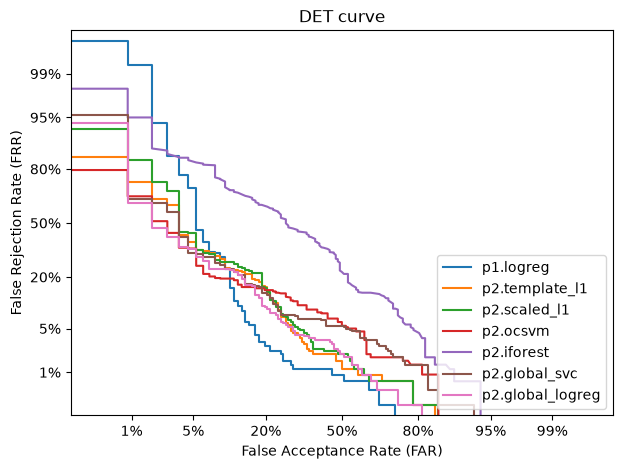

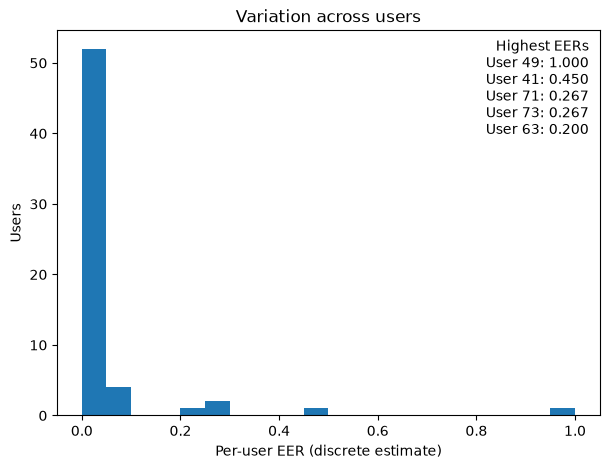

,n_genuine,n_impostor,auc,eer
User ID,,,,
49,5,1,0.000000,1.000000
41,5,2,0.700000,0.450000
71,5,3,0.933333,0.266667
73,5,3,0.933333,0.266667
63,5,1,0.600000,0.200000
37,5,1,0.800000,0.100000
1,5,2,0.900000,0.100000
11,5,1,0.800000,0.100000
32,5,2,0.900000,0.100000


In [5]:
evaluation.plot_det_curves(comparable)
plt.show()
per_user = evaluation.per_user_metrics(comparable["p2.global_logreg"])
evaluation.plot_per_user_eer(per_user)
plt.show()
per_user.sort_values("eer", ascending=False).head(10)


## Within-session warm-up and limits

A genuine user's attempts come from one sitting. Repetition, content
familiarity, and identity are coupled; this experiment cannot establish
cross-day stability or resistance to practised attackers. The plot measures
the span of recorded keyboard events, rather than total GUI completion time.


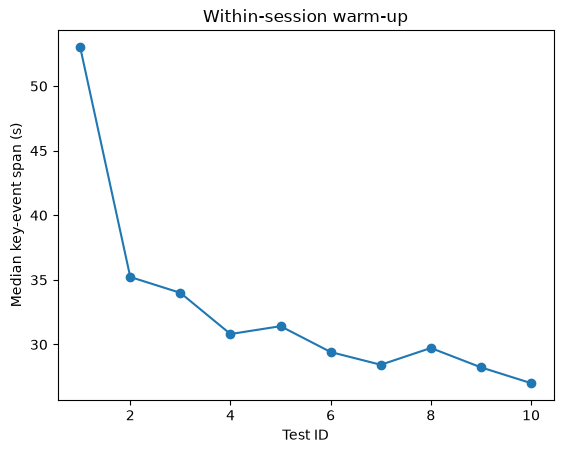

In [6]:
windows = key_events.groupby(level=["User ID", "Is Genuine", "Test ID"])["Epoch"].agg(["min", "max"])
spans = windows["max"] - windows["min"]
genuine_spans = spans.loc[spans.index.get_level_values("Is Genuine")]
genuine_spans.groupby(level="Test ID").median().plot(marker="o", ylabel="Median key-event span (s)", title="Within-session warm-up")
plt.show()


## Reproducibility and MLflow

Save indexed scores, fold IDs, common-probe/per-user tables, resolved settings,
package versions, source hashes, and raw-file checksums under `artifacts/`.
Explicit MLflow logging creates a parent matrix run and one child per complete
configuration. Child runs contain metrics, predictions, per-user tables, and
ROC/DET plots. SQLite tracking and model artifacts use absolute local paths;
`MLFLOW_TRACKING_URI` can select another backend. Scores are not calibrated
probabilities, and no deployment threshold is selected here.


In [7]:
from behavioral_ml.tracking import log_experiments

output_dir = Path("../artifacts")
experiment.write_results(experiments, output_dir, data_dir)
parent_run_id = log_experiments(experiments, output_dir)
print(f"Wrote artifacts to {output_dir.resolve()}; MLflow parent run: {parent_run_id}")


2026/10/28 15:22:21 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Volumes/Workspace/01_Projects/behavioral-ml/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/10/28 15:22:26 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/28 15:22:26 INFO mlflow.store.db.utils: Updating database tables


Wrote artifacts to /Volumes/Workspace/01_Projects/behavioral-ml/artifacts; MLflow parent run: cadd1d9f9a42467db02190fdbb402327
